## 1. Project Overview

Credit card fraud is a major challenge in the financial industry. This project uses Machine Learning techniques to identify potentially fraudulent credit card transactions.

## 2. Project Objective

The main objective is to build and evaluate Machine Learning models that can distinguish between legitimate and fraudulent transactions while handling highly imbalanced data.

## 3. Dataset Information

- Dataset: Credit Card Fraud Detection
- Total Transactions: 284,807
- Total Features: 30 (excluding target variable)
- Target Variable: Class
- Normal Transactions: 284,315
- Fraudulent Transactions: 492

## 4. Tools & Technologies Used

- Python
- Pandas & NumPy
- Matplotlib & Seaborn
- Scikit-learn
- Imbalanced-learn (SMOTE)
- Jupyter Notebook

## 5. Machine Learning Models

- Logistic Regression
- Random Forest Classifier

## 6. Project Workflow

1. Data Loading and Exploration
2. Exploratory Data Analysis (EDA)
3. Class Imbalance Analysis
4. Data Splitting and SMOTE
5. Model Training
6. Model Evaluation
7. Feature Importance Analysis
8. Final Conclusion

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
%pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import imblearn

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
import sys

print("Python Version:", sys.version)

%pip show scikit-learn
%pip show imbalanced-learn
%pip show numpy

Python Version: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
Name: scikit-learn
Version: 1.5.2
Summary: A set of python modules for machine learning and data mining
Home-page: https://scikit-learn.org
Author: 
Author-email: 
License: BSD 3-Clause License

Copyright (c) 2007-2024 The scikit-learn developers.
All rights reserved.

Redistribution and use in source and binary forms, with or without
modification, are permitted provided that the following conditions are met:

* Redistributions of source code must retain the above copyright notice, this
  list of conditions and the following disclaimer.

* Redistributions in binary form must reproduce the above copyright notice,
  this list of conditions and the following disclaimer in the documentation
  and/or other materials provided with the distribution.

* Neither the name of the copyright holder nor the names of its
  contributors may be used to endorse or promote products derived from
  this softwar

In [5]:
%pip show scikit-learn

Name: scikit-learn
Version: 1.5.2
Summary: A set of python modules for machine learning and data mining
Home-page: https://scikit-learn.org
Author: 
Author-email: 
License: BSD 3-Clause License

Copyright (c) 2007-2024 The scikit-learn developers.
All rights reserved.

Redistribution and use in source and binary forms, with or without
modification, are permitted provided that the following conditions are met:

* Redistributions of source code must retain the above copyright notice, this
  list of conditions and the following disclaimer.

* Redistributions in binary form must reproduce the above copyright notice,
  this list of conditions and the following disclaimer in the documentation
  and/or other materials provided with the distribution.

* Neither the name of the copyright holder nor the names of its
  contributors may be used to endorse or promote products derived from
  this software without specific prior written permission.

THIS SOFTWARE IS PROVIDED BY THE COPYRIGHT HOLDERS 

In [6]:
%pip show imbalanced-learn

Name: imbalanced-learn
Version: 0.12.4
Summary: Toolbox for imbalanced dataset in machine learning.
Home-page: https://github.com/scikit-learn-contrib/imbalanced-learn
Author: 
Author-email: 
License: MIT
Location: C:\Users\balde\AppData\Local\Programs\Python\Python311\Lib\site-packages
Requires: joblib, numpy, scikit-learn, scipy, threadpoolctl
Required-by: 
Note: you may need to restart the kernel to use updated packages.


In [7]:
import sklearn
print(sklearn.__version__)

1.5.2


In [8]:
from imblearn.over_sampling import SMOTE

print("SMOTE imported successfully!")

SMOTE imported successfully!


In [9]:
%pip install --force-reinstall scikit-learn==1.5.2 imbalanced-learn==0.12.4

  Using cached scikit_learn-1.5.2-cp311-cp311-win_amd64.whl.metadata (13 kB)
  Using cached imbalanced_learn-0.12.4-py3-none-any.whl.metadata (8.3 kB)
  Using cached numpy-2.4.6-cp311-cp311-win_amd64.whl.metadata (6.6 kB)
  Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl.metadata (60 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.5.2-cp311-cp311-win_amd64.whl (11.0 MB)
Using cached imbalanced_learn-0.12.4-py3-none-any.whl (258 kB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached numpy-2.4.6-cp311-cp311-win_amd64.whl (12.6 MB)
Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl (36.6 MB)
Using cached threadpoolctl-3.8.0-py3-none-any.whl (32 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
  Attempting uninstall: threadpoolctl
    Found existing installation: threadpoolctl 3.

  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
df = pd.read_csv("../Dataset/creditcard.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [12]:
df = pd.read_csv("../Dataset/creditcard.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [13]:
print("Transaction Count:")
print(df["Class"].value_counts())

print("\nTransaction Percentage:")
print(df["Class"].value_counts(normalize=True) * 100)

Transaction Count:
Class
0    284315
1       492
Name: count, dtype: int64

Transaction Percentage:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


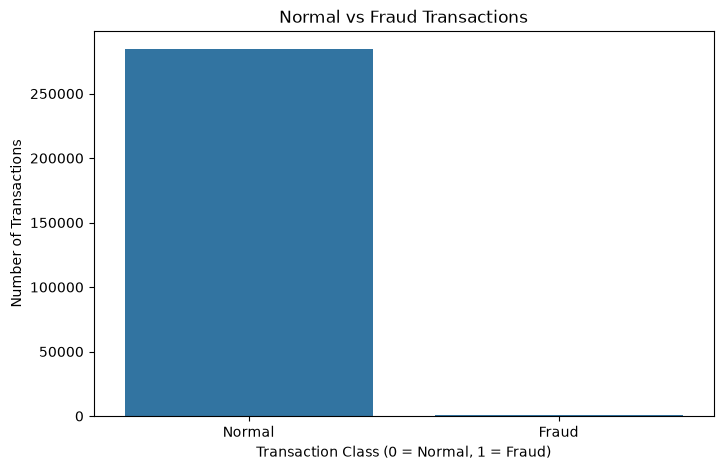

In [14]:
plt.figure(figsize=(8, 5))

sns.countplot(x="Class", data=df)

plt.title("Normal vs Fraud Transactions")
plt.xlabel("Transaction Class (0 = Normal, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Normal", "Fraud"])

plt.show()

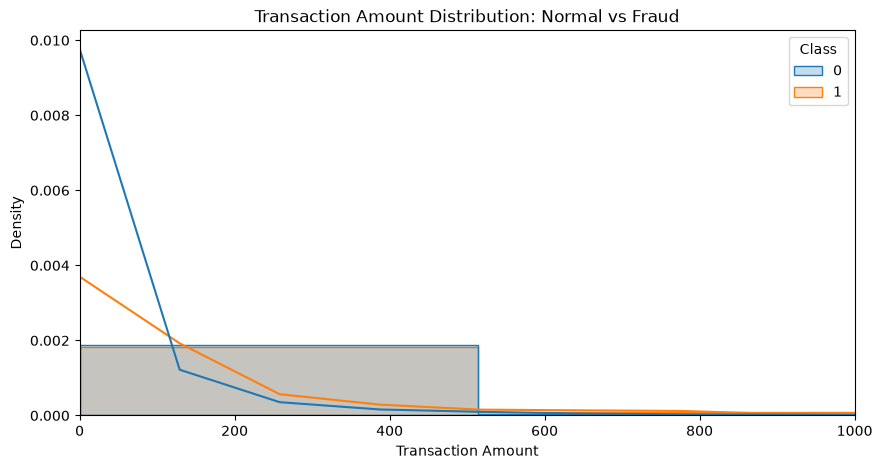

In [15]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="Amount", hue="Class", bins=50, 
             kde=True, element="step", stat="density", common_norm=False)

plt.title("Transaction Amount Distribution: Normal vs Fraud")
plt.xlabel("Transaction Amount")
plt.ylabel("Density")
plt.xlim(0, 1000)

plt.show()

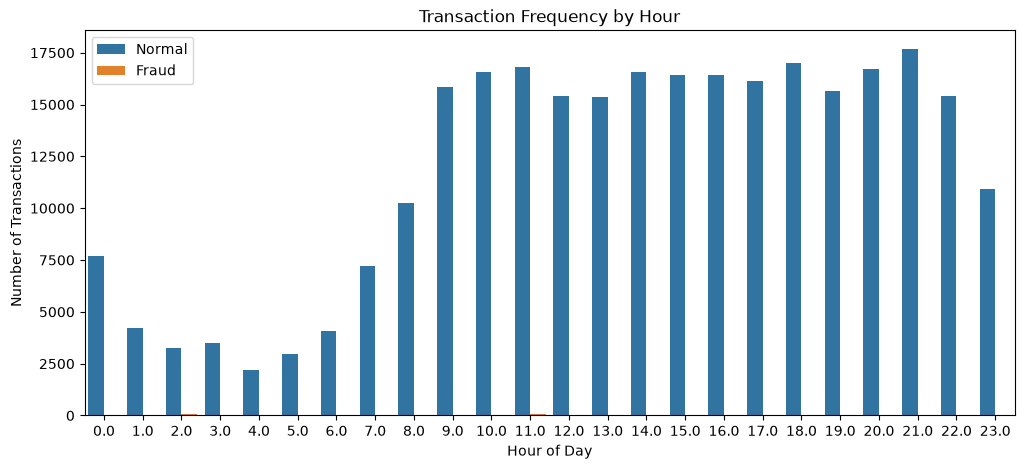

In [16]:
df["Hour"] = (df["Time"] // 3600) % 24

plt.figure(figsize=(12, 5))

sns.countplot(data=df, x="Hour", hue="Class")

plt.title("Transaction Frequency by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Transactions")
plt.legend(labels=["Normal", "Fraud"])

plt.show()

### Why Accuracy Is Misleading in Fraud Detection?

Our dataset is highly imbalanced, with approximately 99.83% normal transactions and only 0.17% fraudulent transactions.

In this situation, accuracy alone is not a reliable evaluation metric.

For example, if a model predicts every transaction as normal, it can achieve approximately 99.83% accuracy while failing to detect even a single fraudulent transaction.

Therefore, we need to focus on Precision, Recall, F1-Score, and AUC-ROC to properly evaluate our fraud detection model.

Recall is particularly important because it tells us how many actual fraudulent transactions are successfully detected by the model.

In [17]:
from sklearn.model_selection import train_test_split

X = df.drop("Class", axis=1)
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nFraud cases in Training Data:", sum(y_train))
print("Fraud cases in Testing Data:", sum(y_test))

Training Data Shape: (227845, 31)
Testing Data Shape: (56962, 31)

Fraud cases in Training Data: 394
Fraud cases in Testing Data: 98


In [18]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_resampled.value_counts())

Before SMOTE:
Class
0    227451
1       394
Name: count, dtype: int64

After SMOTE:
Class
0    227451
1    227451
Name: count, dtype: int64


In [19]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000, random_state=42)

lr_model.fit(X_train_resampled, y_train_resampled)

print("Logistic Regression Model trained successfully!")

Logistic Regression Model trained successfully!


C:\Users\balde\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [20]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_resampled, y_train_resampled)

print("Random Forest Model trained successfully!")

Random Forest Model trained successfully!


In [21]:
lr_predictions = lr_model.predict(X_test)
rf_predictions = rf_model.predict(X_test)

print("Predictions completed successfully!")
print("Logistic Regression Predictions:", len(lr_predictions))
print("Random Forest Predictions:", len(rf_predictions))

Predictions completed successfully!
Logistic Regression Predictions: 56962
Random Forest Predictions: 56962


In [22]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, rf_predictions)
    ],
    "Precision": [
        precision_score(y_test, lr_predictions),
        precision_score(y_test, rf_predictions)
    ],
    "Recall": [
        recall_score(y_test, lr_predictions),
        recall_score(y_test, rf_predictions)
    ],
    "F1-Score": [
        f1_score(y_test, lr_predictions),
        f1_score(y_test, rf_predictions)
    ]
})

results

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.986430,0.103408,0.897959,0.185458
1,Random Forest,0.999456,0.845361,0.836735,0.841026


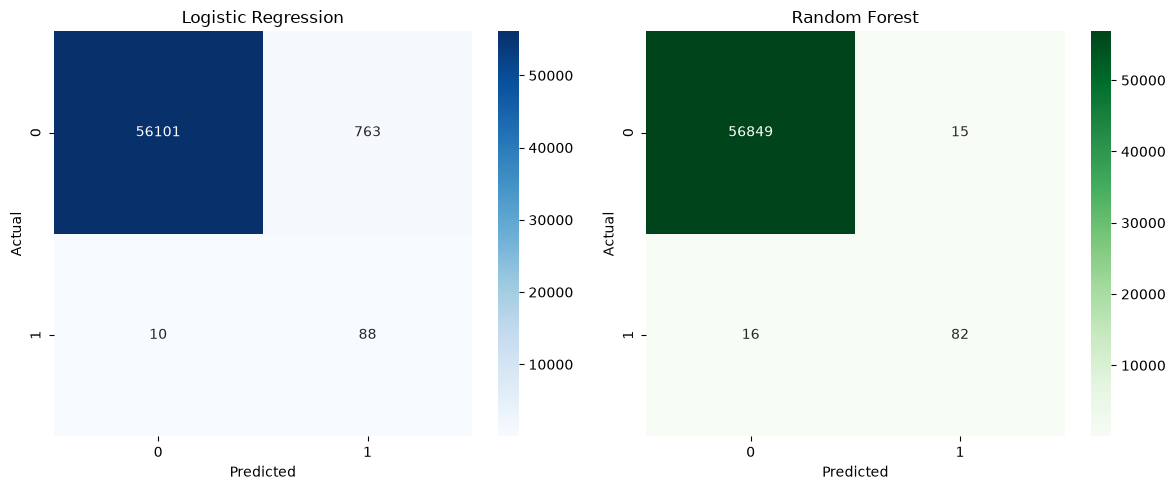

In [23]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_lr = confusion_matrix(y_test, lr_predictions)

sns.heatmap(cm_lr, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

cm_rf = confusion_matrix(y_test, rf_predictions)

sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Greens", ax=axes[1])
axes[1].set_title("Random Forest")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()


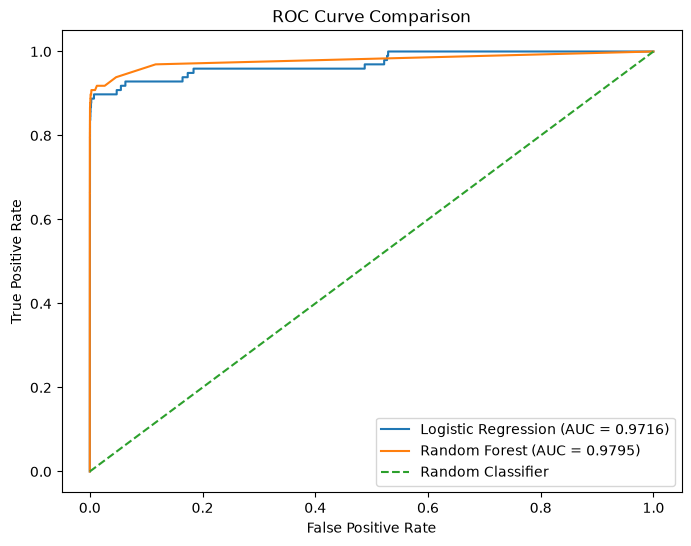

Logistic Regression AUC: 0.9715974670678627
Random Forest AUC: 0.9794597636465954


In [24]:
from sklearn.metrics import roc_curve, roc_auc_score

lr_probabilities = lr_model.predict_proba(X_test)[:, 1]
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

lr_auc = roc_auc_score(y_test, lr_probabilities)
rf_auc = roc_auc_score(y_test, rf_probabilities)

lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_probabilities)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probabilities)

plt.figure(figsize=(8, 6))

plt.plot(lr_fpr, lr_tpr, label=f"Logistic Regression (AUC = {lr_auc:.4f})")
plt.plot(rf_fpr, rf_tpr, label=f"Random Forest (AUC = {rf_auc:.4f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

print("Logistic Regression AUC:", lr_auc)
print("Random Forest AUC:", rf_auc)

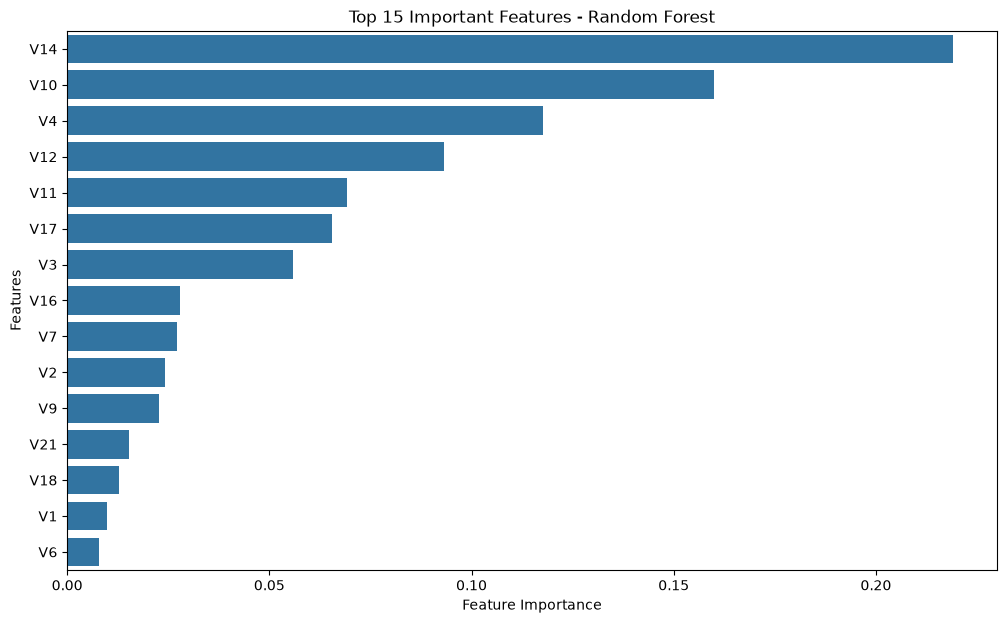

In [25]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Features")

plt.show()

### Most Important Metric in Fraud Detection

Recall is one of the most important evaluation metrics in fraud detection.

It measures how many actual fraudulent transactions are correctly identified by the model.

A low Recall means that many fraudulent transactions are missed, which can lead to financial losses.

In our project, Logistic Regression achieved 89.80% Recall, while Random Forest achieved 83.67% Recall.

Therefore, Logistic Regression is better at identifying fraudulent transactions, while Random Forest provides a better balance between Precision and Recall.

### Scalability: Handling 1 Million Transactions per Hour

A real-world fraud detection system should be capable of processing a large number of transactions efficiently.

To handle 1 million transactions per hour, the following approaches can be used:

1. **Distributed Processing:** Technologies like Apache Spark can process large volumes of transaction data across multiple machines.

2. **Real-Time Processing:** Apache Kafka can be used to receive and stream transactions continuously.

3. **Model Optimization:** Machine Learning models can be optimized to reduce prediction time.

4. **Cloud Infrastructure:** Cloud platforms can provide scalable computing resources according to transaction volume.

5. **Continuous Monitoring:** The system should continuously monitor model performance and update the model when necessary.

By combining these technologies, a fraud detection system can handle high transaction volumes while maintaining efficient performance.

## Final Conclusion

In this project, I analysed credit card transactions to identify fraudulent activities using Machine Learning.

The dataset was highly imbalanced, with only 0.17% fraudulent transactions. To handle this imbalance, I applied SMOTE to the training data.

I trained and evaluated two models: Logistic Regression and Random Forest. Both models were compared using Accuracy, Precision, Recall, F1-Score and ROC-AUC.

Random Forest provided a better overall balance between precision and recall, while Logistic Regression achieved a higher recall, detecting more fraudulent transactions.

This project helped me understand the importance of handling imbalanced datasets, selecting suitable evaluation metrics, and building machine learning models for fraud detection.

In [26]:
import os
import joblib

os.makedirs("../Models", exist_ok=True)

joblib.dump(lr_model, "../Models/logistic_regression.pkl")
joblib.dump(rf_model, "../Models/random_forest.pkl")

print("Both models saved successfully!")

Both models saved successfully!


In [27]:
import os

os.makedirs("../Outputs", exist_ok=True)

results.to_csv("../Outputs/model_comparison.csv", index=False)

feature_importance.to_csv("../Outputs/feature_importance.csv", index=False)

print("Results saved successfully!")

Results saved successfully!


In [28]:
results["ROC-AUC"] = [lr_auc, rf_auc]

results.to_csv("../Outputs/model_comparison.csv", index=False)

results

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.986430,0.103408,0.897959,0.185458,0.971597
1,Random Forest,0.999456,0.845361,0.836735,0.841026,0.979460
